# Miniproyecto 1: Clasificación de MRI con Redes Neuronales Convolucionales para Tipos de Cáncer Cerebral

**Universidad de los Andes — Maestría en Inteligencia Artificial (MAIA)**  
**Curso:** Técnicas de Deep Learning (MAIA-4213)

### Autores
| Nombre Completo | Correo Electrónico | Código |
| :--- | :--- | :--- |
| **Otto Wilmer Castillo Santacruz** | `o.castillos@uniandes.edu.co` | 202611101 |
| **Edgar Andrés Pérez Mora** | `ea.perezm1@uniandes.edu.co` | 200822340 |
| **Silvio Yopasa Romero** | `s.yopasa@uniandes.edu.co` | 202615521 |

---

## Contexto
La resonancia magnética (MRI) desempeña un papel fundamental en la detección y clasificación de los diferentes tipos de cáncer cerebral. La aplicación de redes neuronales convolucionales (CNN) ha incrementado notablemente la precisión en la interpretación de estos volúmenes, al ser entrenadas para reconocer patrones y características distintivas asociadas a cada tipo de tumor. Las resonancias magnéticas (MRI) generan volúmenes tridimensionales compuestos por múltiples capas, donde cada una corresponde a una imagen bidimensional del tejido analizado.

Procesar un volumen completo implica manejar una gran cantidad de datos simultáneamente, lo que resulta computacionalmente costoso y demanda considerables recursos de tiempo y memoria. En este trabajo se emplean exclusivamente imágenes individuales extraídas de las capas de los estudios MRI, en lugar de procesar el volumen tridimensional completo. Esta estrategia transforma el problema en una tarea de clasificación supervisada de imágenes bidimensionales, reduciendo significativamente la carga computacional.

### A. Objetivo
- Desarrollar un método basado en redes neuronales convolucionales que permita clasificar con exactitud imágenes extraídas de estudios MRI en una de las 4 categorías diagnósticas (`glioma`, `meningioma`, `healthy`, `pituitary`).

### B. Conjunto de Datos
- El conjunto de datos comprende $7\,023$ imágenes bidimensionales extraídas de resonancias magnéticas cerebrales adquiridas desde distintos planos anatómicos y disponibles en el dominio público.

---
## 0. Configuración del Entorno e Importación de Librerías
Se importan las librerías requeridas para el procesamiento de imágenes, la manipulación de tensores, el entrenamiento de modelos en PyTorch y el cálculo de métricas de desempeño. Asimismo, se define y ejecuta la función `set_seed(42)` para fijar las semillas pseudoaleatorias (`random`, `numpy` y `torch`) garantizando la reproducibilidad experimental, y se configura automáticamente el dispositivo de aceleración por hardware (`cuda`, `mps` o `cpu`).

In [1]:
import copy
import random
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torchvision.transforms.functional as TF

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

SEED = 42

def set_seed(seed: int = SEED) -> None:
    """Fija las semillas pseudoaleatorias en Python, NumPy y PyTorch para reproducibilidad."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Dispositivo de cómputo activo: {device}")

Dispositivo de cómputo activo: mps


---
## 1. Preparación de las Imágenes para el Entrenamiento y Prueba del Modelo
En esta etapa se estructura el flujo de ingestión, exploración y preprocesamiento de las imágenes de resonancia magnética, garantizando una separación estratificada en subconjuntos de entrenamiento, validación y prueba.

### 1.1. Carga e Indexación del Conjunto de Datos
Se define la ruta de almacenamiento del conjunto de datos, se establecen las 4 categorías diagnósticas (`glioma`, `meningioma`, `healthy`, `pituitary`) y se construye un registro tabular con las rutas de las $7\,023$ imágenes junto con su codificación numérica correspondiente.

In [2]:
CLASSES = ["glioma", "meningioma", "healthy", "pituitary"]
CLASS_TO_IDX = {cls_name: idx for idx, cls_name in enumerate(CLASSES)}
IDX_TO_CLASS = {idx: cls_name for idx, cls_name in enumerate(CLASSES)}

DATA_DIR = Path("./data/brain-tumor-mri-scans")

def collect_image_paths(root_dir: Path, classes: list) -> pd.DataFrame:
    records = []
    
    for file_path in root_dir.rglob("*"):
        if file_path.is_file():
            parent_name = file_path.parent.name.lower()
            for cls_name in classes:
                if cls_name in parent_name:
                    records.append({
                        "filepath": str(file_path.resolve()),
                        "label_name": cls_name,
                        "label": CLASS_TO_IDX[cls_name]
                    })
                    break
    return pd.DataFrame(records)

df_images = collect_image_paths(DATA_DIR, CLASSES)
print(f"Total de imágenes indexadas: {len(df_images)}")
display(df_images.head())

df_images["label_name"].value_counts()

Total de imágenes indexadas: 7023


,filepath,label_name,label
0,/Users/andresperez/Documents/workspace/TDL_Mic...,pituitary,3
1,/Users/andresperez/Documents/workspace/TDL_Mic...,pituitary,3
2,/Users/andresperez/Documents/workspace/TDL_Mic...,pituitary,3
3,/Users/andresperez/Documents/workspace/TDL_Mic...,pituitary,3
4,/Users/andresperez/Documents/workspace/TDL_Mic...,pituitary,3


label_name
healthy       2000
pituitary     1757
meningioma    1645
glioma        1621
Name: count, dtype: int64

### 1.2. Análisis Exploratorio de Datos (EDA)
En primer lugar, se identifican y eliminan las imágenes duplicadas, de modo que todas las estadísticas posteriores describan exactamente el conjunto que se empleará para entrenar y evaluar el modelo. Sobre el conjunto depurado se analiza la distribución de frecuencias absolutas y relativas por categoría diagnóstica con el propósito de identificar posibles desbalances de clase. Adicionalmente, se inspeccionan las dimensiones espaciales de los cortes, se visualiza una muestra representativa de cada clase y se cuantifican los marcos claros presentes en el borde de algunas imágenes.

#### 1.2.1. Eliminación de imágenes duplicadas
Se calcula el hash MD5 del contenido de cada archivo para identificar imágenes idénticas. Se conserva una sola copia por grupo y se descartan por completo los grupos cuyas copias tengan etiquetas contradictorias. El `DataFrame` resultante (`df_clean`) es la base para el resto del EDA, la partición (1.3) y el *pipeline* de transformaciones (1.4).

In [3]:
def file_md5(filepath: str) -> str:
    return hashlib.md5(Path(filepath).read_bytes()).hexdigest()

df_images["md5"] = df_images["filepath"].map(file_md5)
dup_groups = df_images[df_images.duplicated("md5", keep=False)].groupby("md5")
conflicting_md5 = dup_groups["label_name"].nunique().loc[lambda s: s > 1].index

print(f"Grupos de imágenes idénticas: {dup_groups.ngroups}")
print(f"Copias redundantes a eliminar: {df_images.duplicated('md5').sum()}")
print(f"Grupos con etiquetas contradictorias entre copias: {len(conflicting_md5)}")

df_clean = (df_images[~df_images["md5"].isin(conflicting_md5)]
            .sort_values("filepath")
            .drop_duplicates("md5", keep="first")
            .reset_index(drop=True))

df_dedup_summary = pd.DataFrame({
    "antes": df_images["label_name"].value_counts(),
    "despues": df_clean["label_name"].value_counts(),
}).reindex(CLASSES)
df_dedup_summary["eliminadas"] = df_dedup_summary["antes"] - df_dedup_summary["despues"]
df_dedup_summary["despues_%"] = (df_dedup_summary["despues"] / df_dedup_summary["despues"].sum() * 100).round(2)
display(df_dedup_summary)

print(f"Total de imágenes únicas: {len(df_clean)}")

Grupos de imágenes idénticas: 300
Copias redundantes a eliminar: 426
Grupos con etiquetas contradictorias entre copias: 0


,antes,despues,eliminadas,despues_%
label_name,,,,
glioma,1621,1620,1,24.56
meningioma,1645,1531,114,23.21
healthy,2000,1706,294,25.86
pituitary,1757,1740,17,26.38


Total de imágenes únicas: 6597


#### 1.2.2. Distribución de frecuencias absolutas y relativas por categoría diagnóstica
Se cuantifica el número de imágenes por categoría diagnóstica en el conjunto depurado, tanto en valores absolutos como en porcentaje, y se calcula la razón de desbalance (clase mayoritaria / minoritaria). El gráfico de barras compara cada clase con la media por categoría para identificar visualmente posibles desbalances.

,frecuencia_absoluta,frecuencia_relativa_%
label_name,,
glioma,1620,24.56
meningioma,1531,23.21
healthy,1706,25.86
pituitary,1740,26.38


Razón de desbalance (clase mayoritaria / minoritaria): 1.14


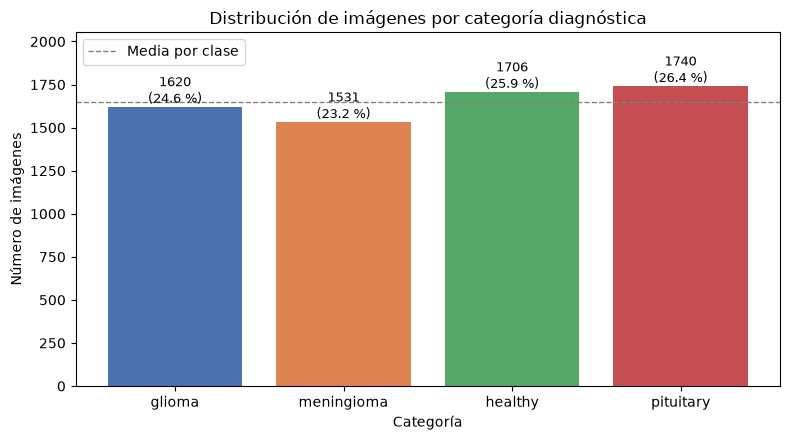

In [4]:
class_counts = df_clean["label_name"].value_counts().reindex(CLASSES)
df_distribution = pd.DataFrame({
    "frecuencia_absoluta": class_counts,
    "frecuencia_relativa_%": (class_counts / class_counts.sum() * 100).round(2)
})
display(df_distribution)

imbalance_ratio = class_counts.max() / class_counts.min()
print(f"Razón de desbalance (clase mayoritaria / minoritaria): {imbalance_ratio:.2f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(CLASSES, class_counts.values, color=["#4C72B0", "#DD8452", "#55A868", "#C44E52"])
for bar, pct in zip(bars, df_distribution["frecuencia_relativa_%"]):
    ax.annotate(f"{int(bar.get_height())}\n({pct:.1f} %)",
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom", fontsize=9)
ax.axhline(class_counts.mean(), color="gray", linestyle="--", linewidth=1, label="Media por clase")
ax.set_title("Distribución de imágenes por categoría diagnóstica")
ax.set_xlabel("Categoría")
ax.set_ylabel("Número de imágenes")
ax.set_ylim(0, class_counts.max() * 1.18)
ax.legend()
plt.tight_layout()
plt.show()

#### 1.2.3. Inspección de dimensiones espaciales y modos de color de los cortes de MRI
Se leen las cabeceras de las imágenes (sin decodificar los píxeles) para obtener su ancho, alto y modo de color. Se reportan el número de resoluciones distintas, el porcentaje de imágenes cuadradas, los estadísticos de dimensiones por categoría y las resoluciones más frecuentes, complementados con un diagrama de dispersión ancho vs. alto y un histograma de la relación de aspecto. El objetivo es definir la estrategia de estandarización espacial y detectar si la resolución varía sistemáticamente entre clases.

Resoluciones distintas: 387
Imágenes cuadradas: 80.13 %

Modos de color:


mode,RGB
label_name,
glioma,1620
meningioma,1531
healthy,1706
pituitary,1740


Estadísticos de dimensiones por categoría:


width              height             
             min median   max    min median   max
label_name                                       
glioma       512  512.0   512    512  512.0   512
meningioma   174  512.0  1275    195  512.0  1427
healthy      150  228.0  1920    168  242.0  1446
pituitary    201  512.0  1365    202  512.0  1365

Resoluciones más frecuentes:


,,frecuencia
width,height,
512,512,4717
225,225,313
630,630,79
201,251,51
228,221,49
300,168,49
232,217,48
150,198,43
200,252,41


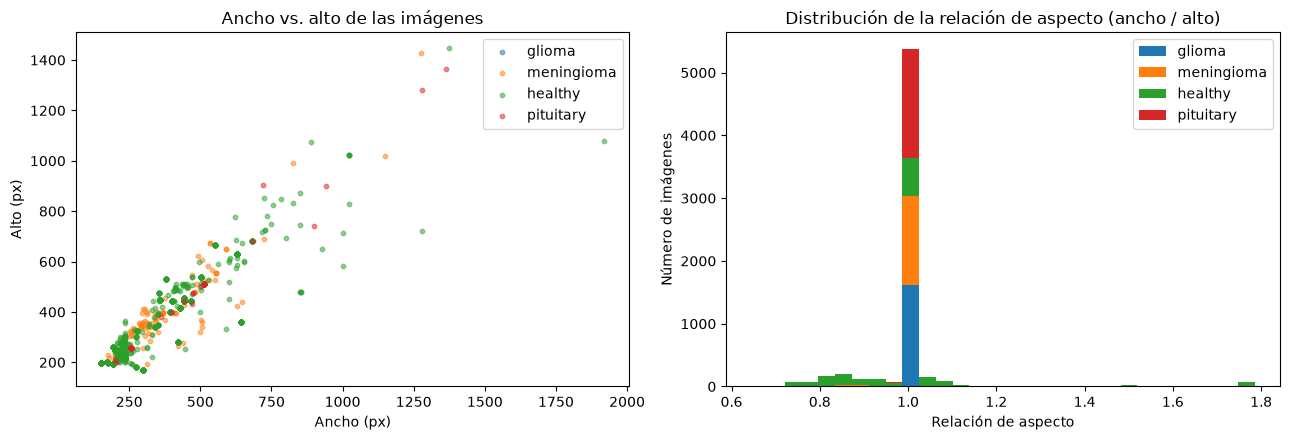

In [5]:
def read_image_metadata(filepath: str) -> dict:
    with Image.open(filepath) as img:
        return {"width": img.width, "height": img.height, "mode": img.mode}

df_meta = pd.concat([df_clean, pd.DataFrame(df_clean["filepath"].map(read_image_metadata).tolist())], axis=1)
df_meta["aspect_ratio"] = df_meta["width"] / df_meta["height"]

print(f"Resoluciones distintas: {df_meta.groupby(['width', 'height']).ngroups}")
print(f"Imágenes cuadradas: {(df_meta['width'] == df_meta['height']).mean() * 100:.2f} %")
print("\nModos de color:")
display(pd.crosstab(df_meta["label_name"], df_meta["mode"]).reindex(CLASSES))

print("Estadísticos de dimensiones por categoría:")
display(df_meta.groupby("label_name")[["width", "height"]]
        .agg(["min", "median", "max"]).reindex(CLASSES))

print("Resoluciones más frecuentes:")
display(df_meta.value_counts(["width", "height"]).head(10).rename("frecuencia").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for cls_name in CLASSES:
    subset = df_meta[df_meta["label_name"] == cls_name]
    axes[0].scatter(subset["width"], subset["height"], s=10, alpha=0.5, label=cls_name)
axes[0].set_title("Ancho vs. alto de las imágenes")
axes[0].set_xlabel("Ancho (px)")
axes[0].set_ylabel("Alto (px)")
axes[0].legend()

axes[1].hist([df_meta.loc[df_meta["label_name"] == c, "aspect_ratio"] for c in CLASSES], bins=30, stacked=True, label=CLASSES)
axes[1].set_title("Distribución de la relación de aspecto (ancho / alto)")
axes[1].set_xlabel("Relación de aspecto")
axes[1].set_ylabel("Número de imágenes")
axes[1].legend()
plt.tight_layout()
plt.show()

#### 1.2.4. Cuantificación de imágenes pequeñas y no cuadradas por categoría
Tomando como referencia el tamaño de entrada objetivo de 224 px, se cuenta por categoría cuántas imágenes tienen el lado menor o ambos lados por debajo de ese tamaño (y, por tanto, requerirían ampliarse) y cuántas se apartan del formato cuadrado (relación de aspecto mayor a 1.1 y a 1.3). Estas cifras sustentan la elección del tamaño de entrada y del relleno a formato cuadrado en el *pipeline* de transformaciones (1.4).

In [6]:
TARGET_SIZE = 224
df_meta["min_side"] = df_meta[["width", "height"]].min(axis=1)
df_meta["max_side"] = df_meta[["width", "height"]].max(axis=1)
df_meta["max_aspect"] = df_meta["max_side"] / df_meta["min_side"]

df_size_issues = df_meta.groupby("label_name").agg(
    total=("filepath", "size"),
    lado_menor_bajo_objetivo=("min_side", lambda s: (s < TARGET_SIZE).sum()),
    ambos_lados_bajo_objetivo=("max_side", lambda s: (s < TARGET_SIZE).sum()),
    aspecto_mayor_1_1=("max_aspect", lambda s: (s > 1.1).sum()),
    aspecto_mayor_1_3=("max_aspect", lambda s: (s > 1.3).sum()),
).reindex(CLASSES)
display(df_size_issues)

,total,lado_menor_bajo_objetivo,ambos_lados_bajo_objetivo,aspecto_mayor_1_1,aspecto_mayor_1_3
label_name,,,,,
glioma,1620,0,0,0,0
meningioma,1531,45,8,76,13
healthy,1706,725,130,720,215
pituitary,1740,2,2,2,0


#### 1.2.5. Visualización de una muestra representativa de cortes de MRI por categoría
Se seleccionan aleatoriamente, con semilla fija para garantizar la reproducibilidad, cinco imágenes por categoría y se muestran en escala de grises junto con su resolución original. La inspección permite reconocer los planos anatómicos y las secuencias de adquisición presentes, así como posibles diferencias visuales entre clases ajenas a la patología.

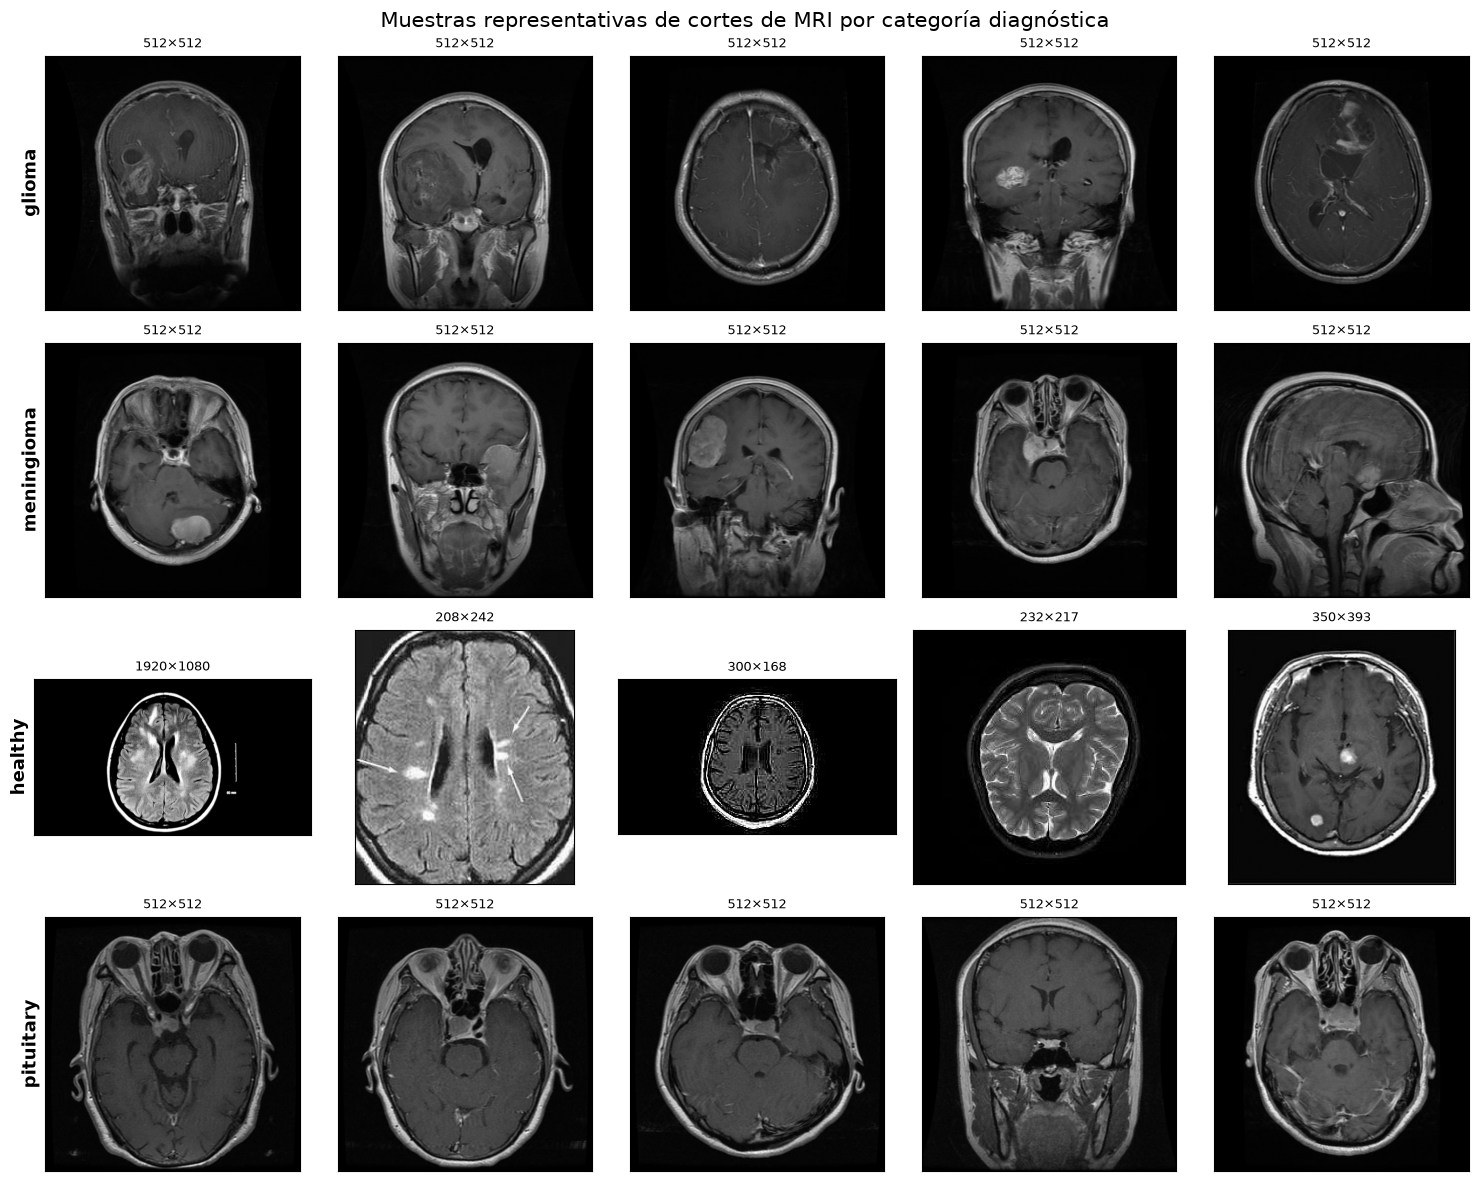

In [7]:
N_SAMPLES_PER_CLASS = 5
rng = np.random.default_rng(42)

fig, axes = plt.subplots(len(CLASSES), N_SAMPLES_PER_CLASS, figsize=(3 * N_SAMPLES_PER_CLASS, 3 * len(CLASSES)))
for row, cls_name in enumerate(CLASSES):
    subset = df_meta[df_meta["label_name"] == cls_name]
    sample_idx = rng.choice(subset.index, size=N_SAMPLES_PER_CLASS, replace=False)
    for col, idx in enumerate(sample_idx):
        record = df_meta.loc[idx]
        with Image.open(record["filepath"]) as img:
            axes[row, col].imshow(img.convert("L"), cmap="gray")
        axes[row, col].set_title(f"{record['width']}×{record['height']}", fontsize=9)
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
    axes[row, 0].set_ylabel(cls_name, fontsize=13, fontweight="bold")
fig.suptitle("Muestras representativas de cortes de MRI por categoría diagnóstica", fontsize=15)
plt.tight_layout()
plt.show()

#### 1.2.6. Detección de marcos claros en el borde de las imágenes
Durante la inspección visual se observó que algunas imágenes incluyen un marco claro de pocos píxeles en su borde, ajeno a la anatomía. Para cuantificarlo, se analizan las 3 líneas exteriores de cada lado y se considera claro un lado cuando la mediana de su intensidad máxima supera 80 (escala 0–255). Las imágenes se clasifican en: sin borde claro, borde parcial (1 a 3 lados) y marco completo (4 lados). El borde parcial puede deberse tanto a marcos incompletos como a anatomía que toca el borde (p. ej. cuello o cráneo en cortes ajustados), mientras que el marco completo corresponde inequívocamente a un artefacto de origen. Se muestran ejemplos de imágenes con marco completo.

frame_type,sin_borde_claro,borde_parcial_1_3_lados,marco_completo_4_lados,con_borde_claro_%,marco_completo_%
label_name,,,,,
glioma,1620,0,0,0.00,0.00
meningioma,1490,36,5,2.68,0.33
healthy,1462,196,48,14.30,2.81
pituitary,1734,3,3,0.34,0.17


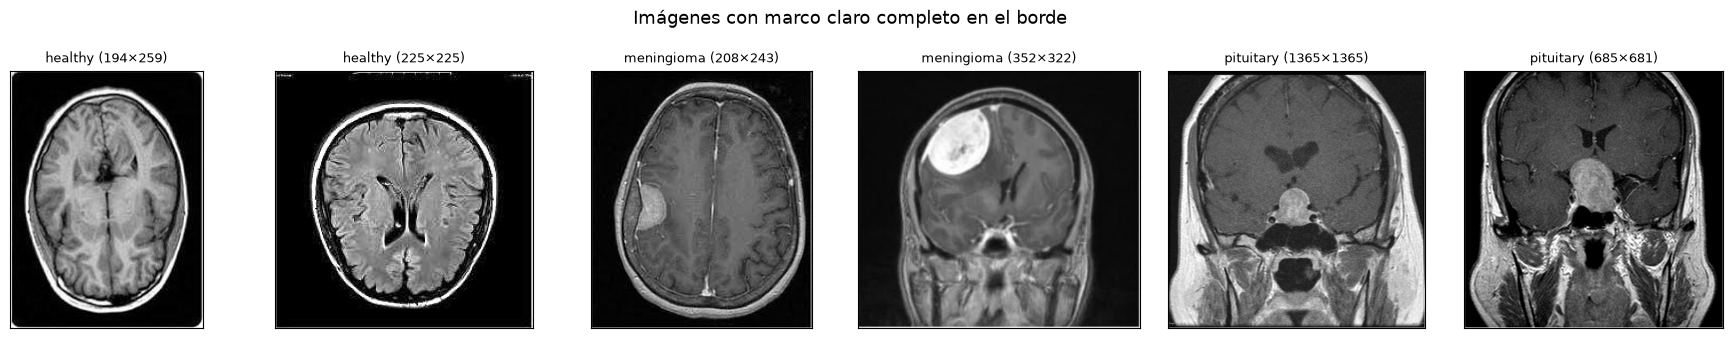

In [8]:
EDGE_WIDTH = 3
EDGE_INTENSITY = 80

def count_bright_sides(filepath: str) -> int:
    with Image.open(filepath) as img:
        gray = np.asarray(img.convert("L"))
    edges = [gray[:EDGE_WIDTH].max(axis=0), gray[-EDGE_WIDTH:].max(axis=0),
        gray[:, :EDGE_WIDTH].max(axis=1), gray[:, -EDGE_WIDTH:].max(axis=1)]
    return sum(np.median(edge) > EDGE_INTENSITY for edge in edges)

df_meta["bright_sides"] = df_meta["filepath"].map(count_bright_sides)
df_meta["frame_type"] = pd.cut(df_meta["bright_sides"], bins=[-1, 0, 3, 4],
labels=["sin_borde_claro", "borde_parcial_1_3_lados", "marco_completo_4_lados"])

frame_counts = pd.crosstab(df_meta["label_name"], df_meta["frame_type"]).reindex(CLASSES)
total = frame_counts.sum(axis=1)
df_frames = frame_counts.assign(**{
    "con_borde_claro_%": ((total - frame_counts["sin_borde_claro"]) / total * 100).round(2),
    "marco_completo_%": (frame_counts["marco_completo_4_lados"] / total * 100).round(2),
})
display(df_frames)

framed = df_meta[df_meta["bright_sides"] == 4]
examples = framed.groupby("label_name", observed=True).head(2).head(6)
fig, axes = plt.subplots(1, len(examples), figsize=(3 * len(examples), 3.4), squeeze=False)
for ax, (_, record) in zip(axes[0], examples.iterrows()):
    with Image.open(record["filepath"]) as img:
        ax.imshow(img.convert("L"), cmap="gray")
    ax.set_title(f"{record['label_name']} ({record['width']}×{record['height']})", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Imágenes con marco claro completo en el borde", fontsize=13)
plt.tight_layout()
plt.show()

#### 1.2.7. Hallazgos del EDA

Todas las cifras corresponden al conjunto depurado ($6\,597$ imágenes únicas).

- **Imágenes duplicadas:** de las $7\,023$ imágenes originales se identificaron 300 grupos de imágenes idénticas (hash MD5) que suman 426 copias redundantes, concentradas en `healthy` (294) y `meningioma` (114). Ninguna copia aparece con etiquetas distintas. Se conserva una sola imagen por grupo antes de cualquier análisis o partición, evitando que copias de una misma imagen sesguen las estadísticas o queden simultáneamente en entrenamiento y prueba (*data leakage*). El hash solo detecta copias exactas: imágenes casi idénticas (reescaladas o recomprimidas) o cortes contiguos de un mismo paciente podrían persistir, y el conjunto no incluye un identificador de paciente que permita controlarlo.
- **Balance de clases:** la distribución es prácticamente balanceada: `pituitary` es la clase mayoritaria (1 740 imágenes, 26.4 %) y `meningioma` la minoritaria (1 531, 23.2 %), con una razón de desbalance de 1.14. No se requieren técnicas agresivas de rebalanceo, aunque se usará partición estratificada, pesos por clase en la función de pérdida y se reportará el *Macro F1-Score* para no favorecer a ninguna categoría.
- **Dimensiones espaciales heterogéneas:** existen 387 resoluciones distintas (de 150 px hasta 1 920 px de lado) y el 80.1 % de las imágenes son cuadradas. Las imágenes pequeñas y no cuadradas se concentran casi exclusivamente en `healthy` (725 con lado menor < 224 px y 720 con relación de aspecto > 1.1) y, en menor medida, en `meningioma` (45 y 76); `glioma` y `pituitary` son prácticamente todas de 512×512 px.
- **Resolución correlacionada con la clase:** el 100 % de `glioma`, el 97.5 % de `pituitary` y el 90.4 % de `meningioma` miden 512×512 px, mientras que solo el 0.9 % de `healthy` tiene esa resolución (mediana ≈ 228×242 px). Esta diferencia de origen puede inducir un **atajo** (*shortcut learning*): la red podría distinguir `healthy` por artefactos de reescalado o nitidez en lugar de por la anatomía. Para mitigarlo, se opta por **reducir** todas las imágenes a 224×224 px en lugar de ampliarlas a 512×512 px: ampliar `healthy` no agrega información y la suavizaría por interpolación. El redimensionamiento común elimina la diferencia de tamaño, pero no necesariamente la de nitidez, ya que las imágenes de 512 px se reducen ≈ 2.2 veces mientras que las de `healthy` quedan cerca de su resolución original; para atenuar este efecto se incorpora un desenfoque gaussiano aleatorio en el aumento de datos de entrenamiento (sección 1.4). Las imágenes no cuadradas se **rellenan con ceros** hasta hacerlas cuadradas antes de redimensionar, evitando tanto la deformación anatómica (escalar una sola dimensión) como la pérdida de contenido (recorte central).
- **Marcos claros en el borde:** el 2.81 % de las imágenes de `healthy` presenta un marco claro completo en sus 4 lados y el 14.30 % algún borde claro, frente a 0.33 % y 2.68 % en `meningioma`, 0.17 % y 0.34 % en `pituitary` y ninguna en `glioma`. Al concentrarse en `healthy`, el marco constituye otro posible **atajo** para identificar la clase y, al rotar con el aumento de datos, delataría la orientación original de la imagen. Por ello, el *pipeline* de transformaciones (1.4) recorta cada imagen a su contenido anatómico antes del relleno y el redimensionamiento, eliminando el marco y los márgenes negros.
- **Modo de color:** todas las imágenes están almacenadas en formato `RGB`, aunque corresponden a cortes en escala de grises; en el *pipeline* (sección 1.4) se conservan los 3 canales estandarizados para mantener una representación uniforme compatible tanto con las arquitecturas convolucionales propuestas (`in_c=3`) como con los transformadores estándar de `torchvision`.

### 1.3. Partición en Conjuntos de Entrenamiento, Validación y Prueba
El conjunto de datos depurado (sin duplicados) se divide de forma estratificada en los subconjuntos de entrenamiento (`Train`, 70 %), validación (`Val`, 15 %) y prueba (`Test`, 15 %), preservando las proporciones originales de cada categoría y evitando la fuga de información (*data leakage*) entre particiones. Se verifica que ninguna imagen aparezca en más de una partición. Adicionalmente, se calculan pesos por clase inversamente proporcionales a su frecuencia en `Train` ($w_c = N / (C \cdot n_c)$) para ponderar la función de pérdida (sección 2.2), de modo que todas las categorías contribuyan por igual al gradiente. Esta etapa solo reparte rutas y etiquetas; el aumento de datos se aplica en la sección 1.4, exclusivamente sobre `Train`.

In [9]:
RANDOM_STATE = 42
VAL_SIZE = 0.15
TEST_SIZE = 0.15

df_train_val, df_test = train_test_split(
    df_clean, test_size=TEST_SIZE, stratify=df_clean["label"], random_state=RANDOM_STATE)
df_train, df_val = train_test_split(
    df_train_val, test_size=VAL_SIZE / (1 - TEST_SIZE), stratify=df_train_val["label"], random_state=RANDOM_STATE)
df_train, df_val, df_test = (df.reset_index(drop=True) for df in (df_train, df_val, df_test))

# Verificación de ausencia de fuga de información entre particiones
splits = {"Train": df_train, "Val": df_val, "Test": df_test}
assert set(df_train["md5"]).isdisjoint(df_val["md5"])
assert set(df_train["md5"]).isdisjoint(df_test["md5"])
assert set(df_val["md5"]).isdisjoint(df_test["md5"])

split_counts = pd.DataFrame({name: df["label_name"].value_counts() for name, df in splits.items()}).reindex(CLASSES)
split_pct = (split_counts / split_counts.sum() * 100).round(2).add_suffix("_%")
df_split_summary = pd.concat([split_counts, split_pct], axis=1)
display(df_split_summary)
print(" | ".join(f"{name}: {len(df)} ({len(df) / len(df_clean) * 100:.1f} %)" for name, df in splits.items()))

# Pesos por clase inversamente proporcionales a su frecuencia en Train, para ponderar la función de pérdida (sección 2.2)
train_counts = df_train["label"].value_counts().sort_index()
CLASS_WEIGHTS = (len(df_train) / (len(CLASSES) * train_counts)).to_numpy(dtype="float32")
display(pd.DataFrame({"imagenes_train": train_counts.to_numpy(), "peso": CLASS_WEIGHTS.round(4)}, index=CLASSES))

,Train,Val,Test,Train_%,Val_%,Test_%
label_name,,,,,,
glioma,1134,243,243,24.56,24.55,24.55
meningioma,1071,230,230,23.20,23.23,23.23
healthy,1194,256,256,25.86,25.86,25.86
pituitary,1218,261,261,26.38,26.36,26.36


Train: 4617 (70.0 %) | Val: 990 (15.0 %) | Test: 990 (15.0 %)


,imagenes_train,peso
glioma,1134,1.0179
meningioma,1071,1.0777
healthy,1194,0.9667
pituitary,1218,0.9477


### 1.4. Pipeline de Transformaciones, `Dataset` y `DataLoaders`
Se establecen las transformaciones de estandarización espacial (recorte al contenido anatómico, relleno con ceros a formato cuadrado y reducción a 224×224 px), conversión a tensor y normalización de intensidad. El recorte al contenido elimina los márgenes negros y los marcos claros presentes en el borde de algunas imágenes, principalmente de `healthy`; de no eliminarse, estos marcos podrían convertirse en un atajo para identificar la clase y, al rotar con el aumento de datos, delatarían la orientación original de la imagen. Además, homogeniza la proporción del cuadro ocupada por el cerebro entre las distintas fuentes. Para el subconjunto de entrenamiento se incorporan técnicas de aumento de datos (*Data Augmentation*) que preservan la etiqueta y corresponden a variaciones reales de la adquisición: volteo horizontal, rotaciones (±10°) y traslaciones (±5 %) leves con relleno negro, variación de brillo y contraste y desenfoque gaussiano aleatorio. Su propósito no es corregir el desbalance (que es leve, se compensa con `CLASS_WEIGHTS` en la función de pérdida y se evalúa sin sesgo mediante el *Macro F1-Score*), sino reducir el sobreajuste: las transformaciones geométricas favorecen la invariancia a la posición, las variaciones de intensidad simulan diferencias entre equipos y secuencias, y el desenfoque aleatorio atenúa el atajo por nitidez identificado en el EDA. La diferencia de tamaño entre clases se resuelve con el redimensionamiento común, no con el aumento. Se descarta el volteo vertical por producir anatomía no plausible. El aumento se aplica únicamente al conjunto de entrenamiento; validación y prueba usan solo las transformaciones de estandarización para no sesgar las métricas. Posteriormente, se instancian las estructuras `Dataset` y `DataLoader` para el suministro eficiente por lotes (*batches*).

#### 1.4.1. Definición de transformaciones, clase `CachedMRIDataset` y generadores `DataLoader`
Se implementan dos transformaciones propias: `CropToContent`, que recorta cada imagen a su contenido anatómico descartando márgenes negros y marcos claros del borde, y `PadToSquare`, que rellena con ceros el lado menor hasta obtener un formato cuadrado. A partir de ellas se componen el preprocesamiento determinista base (`CropToContent`, `PadToSquare` y redimensionamiento a 224×224 px) y los *pipelines* posteriores de evaluación (conversión a tensor y normalización con las estadísticas de ImageNet) y de entrenamiento (que añade el aumento de datos). La clase `CachedMRIDataset` ejecuta el recorte, relleno y redimensionamiento en RAM una sola vez por imagen, evitando repetir la lectura de disco y el recorte en cada época, y aplica bajo demanda las transformaciones de aumento y normalización al construir los `DataLoader` de cada partición.

In [10]:
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 0
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

class CropToContent:
    """Recorta cada corte MRI a su contenido anatómico eliminando márgenes negros y marcos claros."""
    def __init__(self, threshold: int = 20, min_fraction: float = 0.02, band_fraction: float = 0.95,
                 max_band: float = 0.05, border: int = 3, margin: int = 4):
        self.threshold = threshold
        self.min_fraction = min_fraction
        self.band_fraction = band_fraction
        self.max_band = max_band
        self.border = border
        self.margin = margin

    def _content_range(self, fraction: np.ndarray) -> tuple:
        n = len(fraction)
        start, end = self.border, n - self.border
        limit = int(self.max_band * n)
        while start < limit and fraction[start] >= self.band_fraction:
            start += 1
        while end > n - limit and fraction[end - 1] >= self.band_fraction:
            end -= 1
        idx = start + np.flatnonzero(fraction[start:end] > self.min_fraction)
        if idx.size == 0:
            return 0, n
        return max(idx[0] - self.margin, start), min(idx[-1] + self.margin + 1, end)

    def __call__(self, img: Image.Image) -> Image.Image:
        mask = np.asarray(img.convert("L")) > self.threshold
        top, bottom = self._content_range(mask.mean(axis=1))
        left, right = self._content_range(mask.mean(axis=0))
        return img.crop((left, top, right, bottom))

class PadToSquare:
    """Rellena simétricamente con ceros el lado menor de la imagen hasta obtener formato cuadrado."""
    def __call__(self, img: Image.Image) -> Image.Image:
        w, h = img.size
        side = max(w, h)
        left, top = (side - w) // 2, (side - h) // 2
        return TF.pad(img, [left, top, side - w - left, side - h - top], fill=0)

base_transform = [CropToContent(), PadToSquare(), transforms.Resize((IMG_SIZE, IMG_SIZE), antialias=True)]
aug_transforms = [
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=10, translate=(0.05, 0.05), fill=0),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.RandomApply([transforms.GaussianBlur(kernel_size=3)], p=0.3),
]
tensor_transform = [transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]

# Pipelines completos (para inspección visual a partir de imágenes crudas)
train_transform = transforms.Compose(base_transform + aug_transforms + tensor_transform)
eval_transform = transforms.Compose(base_transform + tensor_transform)

# Pipelines post-caché (operan sobre imágenes ya recortadas y redimensionadas en RAM)
aug_post_tf = transforms.Compose(aug_transforms + tensor_transform)
eval_post_tf = transforms.Compose(tensor_transform)

class CachedMRIDataset(Dataset):
    """Pre-procesa CropToContent + PadToSquare + Resize en RAM una sola vez por archivo."""
    _cache = {}

    def __init__(self, df: pd.DataFrame, post_transform=None):
        self.filepaths = df["filepath"].tolist()
        self.labels = df["label"].tolist()
        self.post_transform = post_transform
        base_tf = transforms.Compose(base_transform)
        self.images = []
        for fp in self.filepaths:
            if fp not in self._cache:
                with Image.open(fp) as img:
                    self._cache[fp] = base_tf(img.convert("RGB"))
            self.images.append(self._cache[fp])

    def __len__(self) -> int:
        return len(self.images)

    def __getitem__(self, idx: int):
        img = self.images[idx]
        if self.post_transform:
            img = self.post_transform(img)
        return img, self.labels[idx]

train_dataset = CachedMRIDataset(df_train, aug_post_tf)
val_dataset = CachedMRIDataset(df_val, eval_post_tf)
test_dataset = CachedMRIDataset(df_test, eval_post_tf)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

print(f"Lotes — Train: {len(train_loader)} | Val: {len(val_loader)} | Test: {len(test_loader)}")
images, labels = next(iter(train_loader))
print(f"Forma de un lote: {tuple(images.shape)} | Etiquetas: {tuple(labels.shape)}")

Lotes — Train: 145 | Val: 31 | Test: 31
Forma de un lote: (32, 3, 224, 224) | Etiquetas: (32,)


#### 1.4.2. Verificación visual del pipeline de transformaciones sobre una imagen no cuadrada
Se selecciona una imagen no cuadrada del conjunto y se muestra junto con su versión estandarizada (*pipeline* de validación y prueba) y cuatro variantes generadas por el *pipeline* de entrenamiento, con semilla fija para reproducibilidad. Esta inspección permite comprobar que el recorte elimina márgenes y marcos sin perder anatomía, que el relleno conserva la proporción original y que el aumento de datos produce variaciones plausibles sin introducir artefactos.

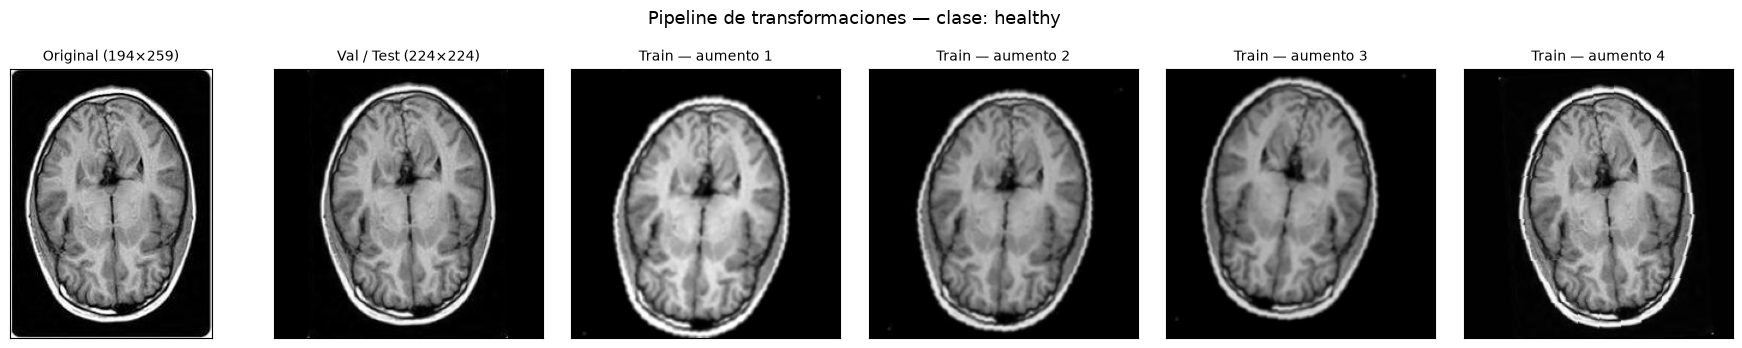

In [11]:
# Verificación visual del pipeline de transformaciones sobre una imagen no cuadrada
N_AUGMENTED = 4
torch.manual_seed(42)

sample_record = df_meta[df_meta["max_aspect"] > 1.3].iloc[0]
with Image.open(sample_record["filepath"]) as img:
    sample_img = img.convert("RGB")

def denormalize(tensor: torch.Tensor) -> np.ndarray:
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (tensor * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(1, N_AUGMENTED + 2, figsize=(3 * (N_AUGMENTED + 2), 3.5))
axes[0].imshow(sample_img)
axes[0].set_title(f"Original ({sample_img.width}×{sample_img.height})", fontsize=10)
axes[1].imshow(denormalize(eval_transform(sample_img)))
axes[1].set_title(f"Val / Test ({IMG_SIZE}×{IMG_SIZE})", fontsize=10)
for k in range(N_AUGMENTED):
    axes[k + 2].imshow(denormalize(train_transform(sample_img)))
    axes[k + 2].set_title(f"Train — aumento {k + 1}", fontsize=10)
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle(f"Pipeline de transformaciones — clase: {sample_record['label_name']}", fontsize=13)
plt.tight_layout()
plt.show()

---
## 2. Desarrollo y Selección de la Arquitectura de Red Neuronal Convolucional (CNN)
En esta sección se formula, evalúa y selecciona la arquitectura de red neuronal convolucional orientada a la clasificación de los cortes de MRI en las 4 categorías diagnósticas (`glioma`, `meningioma`, `healthy`, `pituitary`). En lugar de fijar arbitrariamente una única topología desde el inicio, se adopta una metodología experimental en dos etapas:
1. **Exploración rápida sobre una muestra estratificada:** Se extrae un subconjunto representativo del dataset para poner a prueba distintas arquitecturas candidatas y esquemas de regularización/optimización en un tiempo acotado.
2. **Selección y entrenamiento del modelo final:** A partir de la comparación cuantitativa de las arquitecturas evaluadas, se selecciona la que obtiene mejores resultados para entrenar el modelo definitivo sobre el $100\,\%$ de los datos.

### 2.1. Descripción y Definición de las Arquitecturas Candidatas

Se diseñan cuatro configuraciones candidatas para evaluar el impacto de la profundidad, el tamaño del campo receptivo por bloque, el tipo de agrupación global (*Global Pooling*) y la estabilidad del planificador de tasa de aprendizaje.

#### 2.1.1. Arquitecturas 1 y 2 — `BaselineCNN` (4 bloques simples + `AvgPool`)
- **Arquitectura 1 (`BaselineCNN` con `ReduceLROnPlateau`):** Red convolucional base compuesta por cuatro bloques secuenciales ($3 \to 32 \to 64 \to 128 \to 256$ canales). Cada bloque aplica una sola capa `Conv2d(3×3, padding=1, bias=False)`, seguida de `BatchNorm2d`, activación `ReLU` y reducción espacial `MaxPool2d(2, 2)` ($224 \to 112 \to 56 \to 28 \to 14$). Al final aplica `AdaptiveAvgPool2d((1, 1))` y un clasificador denso ($256 \to 128 \to 4$) con `Dropout(p=0.4)` ($422\,308$ parámetros), entrenada con `AdamW(lr=1e-3)` y planificador `ReduceLROnPlateau(patience=2)`.
- **Arquitectura 2 (`BaselineCNN` con `CosineAnnealingLR` + `Label Smoothing` + `GradClip`):** Conserva exactamente la misma clase `BaselineCNN` de $422\,308$ parámetros, pero reemplaza el planificador por `CosineAnnealingLR` (`lr=8e-4 -> 1e-5`), añade suavizado de etiquetas (`label_smoothing=0.05`) en la función de pérdida ponderada para evitar sobreconfianza en cortes ambiguos, e incorpora recorte de gradiente (`clip_grad_norm_=2.0`) para suprimir los picos de inestabilidad de `BatchNorm2d` en validación.

In [12]:
class BaselineCNN(nn.Module):
    """Arquitectura 1 y 2: 4 bloques convolucionales simples + AdaptiveAvgPool2d + cabezal denso."""
    def __init__(self, num_classes: int = 4, dropout_p: float = 0.4):
        super().__init__()
        def conv_block(in_c: int, out_c: int) -> nn.Sequential:
            return nn.Sequential(
                nn.Conv2d(in_c, out_c, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_c),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(kernel_size=2, stride=2)
            )
        self.features = nn.Sequential(
            conv_block(3, 32),
            conv_block(32, 64),
            conv_block(64, 128),
            conv_block(128, 256)
        )
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout_p),
            nn.Linear(128, num_classes)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.classifier(self.global_pool(self.features(x)))

#### 2.1.2. Arquitectura 3 — `Deep5BlockCNN` (5 bloques simples hasta $512$ canales + `DualPool`)
Extiende la profundidad a cinco bloques convolucionales ($3 \to 32 \to 64 \to 128 \to 256 \to 512$ canales, reduciendo la resolución espacial a $7 \times 7$) sin conexiones residuales ($1\,833\,252$ parámetros) e incorpora agrupación global dual (`AdaptiveAvgPool2d` + `AdaptiveMaxPool2d`) seguida de un clasificador denso ($1024 \to 256 \to 4$) con `BatchNorm1d(256)`, `ReLU` y `Dropout(p=0.3)`. Se entrena bajo el mismo esquema estabilizado (`AdamW` con `lr=8e-4`, `CosineAnnealingLR`, `label_smoothing=0.05` y `clip_grad_norm_=2.0`) con el propósito de evaluar el efecto de incrementar la profundidad y cuadruplicar el número de parámetros frente a la arquitectura base.

In [13]:
class Deep5BlockCNN(nn.Module):
    """Arquitectura 3: 5 bloques convolucionales simples (hasta 512 canales) + Dual Pooling."""
    def __init__(self, num_classes: int = 4, dropout_p: float = 0.3):
        super().__init__()
        def conv_block(in_c: int, out_c: int) -> nn.Sequential:
            return nn.Sequential(
                nn.Conv2d(in_c, out_c, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_c),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(kernel_size=2, stride=2)
            )
        self.features = nn.Sequential(
            conv_block(3, 32),
            conv_block(32, 64),
            conv_block(64, 128),
            conv_block(128, 256),
            conv_block(256, 512)
        )
        self.avg_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.max_pool = nn.AdaptiveMaxPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Linear(512 * 2, 256, bias=False),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout_p),
            nn.Linear(256, num_classes)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        feat = self.features(x)
        pooled = torch.cat([self.avg_pool(feat).flatten(1), self.max_pool(feat).flatten(1)], dim=1)
        return self.classifier(pooled)

#### 2.1.3. Arquitectura 4 — `DoubleConvMRICNN` (4 bloques de Doble Convolución $3 \times 3$ + `DualPool(Avg+Max)` + `BatchNorm1d`)
Mantiene 4 niveles espaciales ($224 \to 14$), pero sustituye cada bloque simple por un **bloque de doble convolución consecutiva** (`Conv2d(3×3) -> BN -> ReLU -> Conv2d(3×3) -> BN -> ReLU -> MaxPool2d`). Dos convoluciones de $3 \times 3$ en serie equivalen a un campo receptivo efectivo de $5 \times 5$ con doble no-linealidad por etapa, capturando mejor la diferencia entre bordes difusos (`glioma`) y bordes bien delimitados (`meningioma`). Al término del cuarto bloque concatena `AdaptiveAvgPool2d((1, 1))` (contexto global del corte) y `AdaptiveMaxPool2d((1, 1))` (respuesta máxima focalizada en el tumor), pasando el vector de $512$ características a un cabezal denso ($512 \to 128 \to 4$) con `BatchNorm1d(128)`, `ReLU` y `Dropout(p=0.3)` ($1\,239\,524$ parámetros), entrenada con `AdamW(lr=6e-4, weight_decay=1e-4)`, `CosineAnnealingLR`, `label_smoothing=0.05` y recorte de gradiente (`max_norm=2.0`).

In [14]:
class DoubleConvMRICNN(nn.Module):
    """Arquitectura 4: 4 bloques de Doble Convolución 3x3 + Dual Global Pooling (Avg+Max) + BatchNorm1d."""
    def __init__(self, num_classes: int = 4, dropout_p: float = 0.3):
        super().__init__()
        def double_block(in_c: int, out_c: int) -> nn.Sequential:
            return nn.Sequential(
                nn.Conv2d(in_c, out_c, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_c),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_c, out_c, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_c),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(kernel_size=2, stride=2)
            )
        self.features = nn.Sequential(
            double_block(3, 32),
            double_block(32, 64),
            double_block(64, 128),
            double_block(128, 256)
        )
        self.avg_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.max_pool = nn.AdaptiveMaxPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Linear(256 * 2, 128, bias=False),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout_p),
            nn.Linear(128, num_classes)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        feat = self.features(x)
        pooled = torch.cat([self.avg_pool(feat).flatten(1), self.max_pool(feat).flatten(1)], dim=1)
        return self.classifier(pooled)

### 2.2. Extracción de Muestra Estratificada (Exclusivamente desde `Train`) y Pruebas de Arquitecturas Candidatas
Para evitar cualquier fuga de información o sesgo de selección sobre los conjuntos globales de validación (`df_val`) y prueba (`df_test`), el subconjunto de exploración (`df_sub`, 30 % de `df_train`) se extrae **exclusivamente a partir de la partición de entrenamiento (`df_train`)** y se subdivide internamente de forma estratificada en `df_sub_train` (70 %, $969$ imágenes), `df_sub_val` (15 %, $208$ imágenes) y `df_sub_test` (15 %, $208$ imágenes). De este modo, `df_val` y `df_test` permanecen completamente intactos hasta el entrenamiento y evaluación del modelo definitivo. Asimismo, se define la función auxiliar `evaluate` (que calcula pérdida ponderada, exactitud y *Macro F1-Score* sin suavizado de etiquetas) y se ejecuta la búsqueda comparativa `run_architecture_search` durante 15 épocas reutilizando las imágenes pre-procesadas en RAM por `CachedMRIDataset`.

In [15]:
@torch.no_grad()
def evaluate(model, dataloader, criterion, device):
    """Evalúa el modelo sin cálculo de gradientes y retorna pérdida, exactitud, Macro F1 y predicciones."""
    model.eval()
    running_loss = torch.zeros((), device=device)
    all_preds, all_targets = [], []

    for inputs, targets in dataloader:
        inputs, targets = inputs.to(device), targets.to(device)
        logits = model(inputs)
        loss = criterion(logits, targets)

        running_loss += loss.detach() * inputs.size(0)
        all_preds.append(logits.argmax(dim=1))
        all_targets.append(targets)

    epoch_loss = (running_loss / len(dataloader.dataset)).item()
    y_pred = torch.cat(all_preds).cpu().numpy()
    y_true = torch.cat(all_targets).cpu().numpy()
    epoch_acc = accuracy_score(y_true, y_pred)
    epoch_f1 = f1_score(y_true, y_pred, average="macro")
    return epoch_loss, epoch_acc, epoch_f1, y_true, y_pred


SUBSET_FRAC = 0.30
df_sub, _ = train_test_split(
    df_train, train_size=SUBSET_FRAC, stratify=df_train["label"], random_state=RANDOM_STATE
)
df_sub_train_val, df_sub_test = train_test_split(
    df_sub, test_size=TEST_SIZE, stratify=df_sub["label"], random_state=RANDOM_STATE
)
df_sub_train, df_sub_val = train_test_split(
    df_sub_train_val, test_size=VAL_SIZE / (1 - TEST_SIZE), stratify=df_sub_train_val["label"], random_state=RANDOM_STATE
)
df_sub_train, df_sub_val, df_sub_test = (
    df.reset_index(drop=True) for df in (df_sub_train, df_sub_val, df_sub_test)
)

# Verificación de que el subconjunto proviene exclusivamente de df_train (sin tocar df_val ni df_test)
assert set(df_sub["md5"]).issubset(df_train["md5"])
assert set(df_sub["md5"]).isdisjoint(df_val["md5"])
assert set(df_sub["md5"]).isdisjoint(df_test["md5"])
assert set(df_sub_train["md5"]).isdisjoint(df_sub_val["md5"])
assert set(df_sub_train["md5"]).isdisjoint(df_sub_test["md5"])
assert set(df_sub_val["md5"]).isdisjoint(df_sub_test["md5"])
print(f"Subconjunto estratificado de exploración (desde Train) -> Sub-Train: {len(df_sub_train)} | Sub-Val: {len(df_sub_val)} | Sub-Test: {len(df_sub_test)}")

def run_architecture_search(candidates_config, sub_train_df, sub_val_df, sub_test_df, epochs: int = 15):
    """Entrena y compara las arquitecturas candidatas sobre el subconjunto estratificado."""
    sub_train_ds = CachedMRIDataset(sub_train_df, aug_post_tf)
    sub_val_ds = CachedMRIDataset(sub_val_df, eval_post_tf)
    sub_test_ds = CachedMRIDataset(sub_test_df, eval_post_tf)

    sub_val_loader = DataLoader(sub_val_ds, batch_size=BATCH_SIZE, shuffle=False)
    sub_test_loader = DataLoader(sub_test_ds, batch_size=BATCH_SIZE, shuffle=False)
    eval_crit = nn.CrossEntropyLoss(weight=torch.tensor(CLASS_WEIGHTS, dtype=torch.float32, device=device))
    results = []

    for name, model_cls, lr, sched_type, smooth in candidates_config:
        torch.manual_seed(RANDOM_STATE)
        sub_train_loader = DataLoader(sub_train_ds, batch_size=BATCH_SIZE, shuffle=True)
        model = model_cls(num_classes=len(CLASSES)).to(device)
        params = sum(p.numel() for p in model.parameters() if p.requires_grad)

        train_crit = nn.CrossEntropyLoss(
            weight=torch.tensor(CLASS_WEIGHTS, dtype=torch.float32, device=device),
            label_smoothing=smooth
        )
        opt = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
        sched = (optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=2)
                 if sched_type == "plateau"
                 else optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=1e-5))

        best_val_loss, best_val_acc = float("inf"), 0.0
        best_wts = copy.deepcopy(model.state_dict())
        val_losses = []

        for _ in range(epochs):
            model.train()
            for x, y in sub_train_loader:
                x, y = x.to(device), y.to(device)
                opt.zero_grad(set_to_none=True)
                loss = train_crit(model(x), y)
                loss.backward()
                if smooth > 0:
                    nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
                opt.step()

            vl, va, _, _, _ = evaluate(model, sub_val_loader, eval_crit, device)
            val_losses.append(vl)
            sched.step(vl) if sched_type == "plateau" else sched.step()
            if vl < best_val_loss:
                best_val_loss, best_val_acc = vl, va
                best_wts = copy.deepcopy(model.state_dict())

        model.load_state_dict(best_wts)
        tl, ta, tf_m, yt, yp = evaluate(model, sub_test_loader, eval_crit, device)
        rep = classification_report(yt, yp, target_names=CLASSES, output_dict=True, zero_division=0)

        print(f"\n[{name}] ({params:,} params)")
        print(f"  Best Val Loss: {best_val_loss:.4f} (Max Spike: {np.max(val_losses):.4f}, Std: {np.std(val_losses):.4f}) | Best Val Acc: {best_val_acc:.4f}")
        print(f"  TEST -> Loss: {tl:.4f} | Acc: {ta:.4f} | Macro F1: {tf_m:.4f}")
        print(f"  F1 por clase -> Glioma: {rep['glioma']['f1-score']:.4f} | Meningioma: {rep['meningioma']['f1-score']:.4f} | Healthy: {rep['healthy']['f1-score']:.4f} | Pituitary: {rep['pituitary']['f1-score']:.4f}")

        results.append({
            "Arquitectura": name,
            "Parámetros": params,
            "Best_Val_Loss": round(best_val_loss, 4),
            "Val_Acc_%": round(best_val_acc * 100, 2),
            "Test_Loss": round(tl, 4),
            "Test_Acc_%": round(ta * 100, 2),
            "Test_Macro_F1_%": round(tf_m * 100, 2),
            "F1_Glioma_%": round(rep["glioma"]["f1-score"] * 100, 2),
            "F1_Meningioma_%": round(rep["meningioma"]["f1-score"] * 100, 2),
            "F1_Healthy_%": round(rep["healthy"]["f1-score"] * 100, 2),
            "F1_Pituitary_%": round(rep["pituitary"]["f1-score"] * 100, 2),
        })
    return pd.DataFrame(results)

candidates_config = [
    ("1. BaselineCNN (Plateau, lr=1e-3)", BaselineCNN, 1e-3, "plateau", 0.0),
    ("2. BaselineCNN + CosineLR + Smooth", BaselineCNN, 8e-4, "cosine", 0.05),
    ("3. Deep5BlockCNN (5 bloques, 512 ch)", Deep5BlockCNN, 8e-4, "cosine", 0.05),
    ("4. DoubleConvMRICNN (Doble Conv + DualPool)", DoubleConvMRICNN, 6e-4, "cosine", 0.05),
]

df_arch_comparison = run_architecture_search(
    candidates_config, df_sub_train, df_sub_val, df_sub_test, epochs=15
)

Subconjunto estratificado de exploración (desde Train) -> Sub-Train: 969 | Sub-Val: 208 | Sub-Test: 208

[1. BaselineCNN (Plateau, lr=1e-3)] (422,308 params)
  Best Val Loss: 0.4972 (Max Spike: 2.1688, Std: 0.4370) | Best Val Acc: 0.7933
  TEST -> Loss: 0.4641 | Acc: 0.8029 | Macro F1: 0.7930
  F1 por clase -> Glioma: 0.8174 | Meningioma: 0.5977 | Healthy: 0.9346 | Pituitary: 0.8224

[2. BaselineCNN + CosineLR + Smooth] (422,308 params)
  Best Val Loss: 0.4672 (Max Spike: 1.2724, Std: 0.2510) | Best Val Acc: 0.8510
  TEST -> Loss: 0.4624 | Acc: 0.8510 | Macro F1: 0.8456
  F1 por clase -> Glioma: 0.8108 | Meningioma: 0.7500 | Healthy: 0.9643 | Pituitary: 0.8571

[3. Deep5BlockCNN (5 bloques, 512 ch)] (1,833,252 params)
  Best Val Loss: 0.1996 (Max Spike: 1.7304, Std: 0.3999) | Best Val Acc: 0.9423
  TEST -> Loss: 0.1566 | Acc: 0.9375 | Macro F1: 0.9359
  F1 por clase -> Glioma: 0.9505 | Meningioma: 0.8842 | Healthy: 0.9818 | Pituitary: 0.9273

[4. DoubleConvMRICNN (Doble Conv + DualPool

### 2.3. Comparación de Resultados de cada Arquitectura y Selección del Modelo Final
En esta subsección se contrastan los resultados cuantitativos obtenidos por las cuatro arquitecturas candidatas sobre el subconjunto de exploración extraído exclusivamente desde `df_train` (`Sub-Train: 969 | Sub-Val: 208 | Sub-Test: 208`, 15 épocas), comparando tanto las métricas globales (`Test Loss`, `Test Accuracy`, `Test Macro F1`) como el desempeño desagregado por patología:

,Arquitectura,Parámetros,Best_Val_Loss,Val_Acc_%,Test_Loss,Test_Acc_%,Test_Macro_F1_%,F1_Glioma_%,F1_Meningioma_%,F1_Healthy_%,F1_Pituitary_%
0,"1. BaselineCNN (Plateau, lr=1e-3)",422308,0.4972,79.33,0.4641,80.29,79.30,81.74,59.77,93.46,82.24
1,2. BaselineCNN + CosineLR + Smooth,422308,0.4672,85.10,0.4624,85.10,84.56,81.08,75.00,96.43,85.71
2,"3. Deep5BlockCNN (5 bloques, 512 ch)",1833252,0.1996,94.23,0.1566,93.75,93.59,95.05,88.42,98.18,92.73
3,4. DoubleConvMRICNN (Doble Conv + DualPool),1239524,0.2433,92.31,0.1684,96.15,95.99,96.15,92.31,97.30,98.18


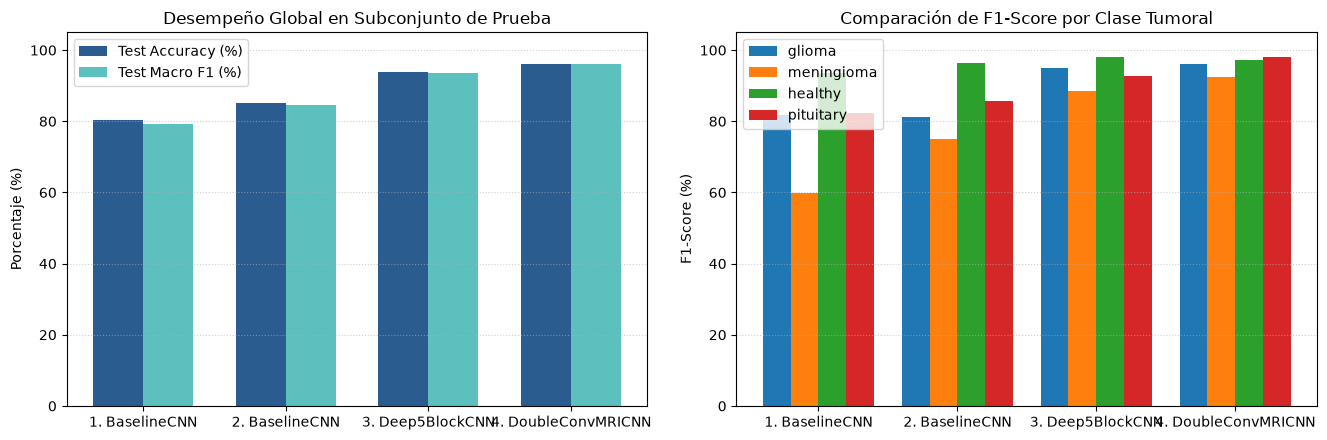

In [16]:
# Visualización tabular y gráfica de df_arch_comparison generado en la sección 2.2
display(df_arch_comparison)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))
short_names = [f"{i + 1}. {row.split()[1]}" for i, row in enumerate(df_arch_comparison["Arquitectura"])]
x = np.arange(len(short_names))
width = 0.35

axes[0].bar(x - width / 2, df_arch_comparison["Test_Acc_%"], width, label="Test Accuracy (%)", color="#2b5c8f")
axes[0].bar(x + width / 2, df_arch_comparison["Test_Macro_F1_%"], width, label="Test Macro F1 (%)", color="#5bc0be")
axes[0].set_xticks(x)
axes[0].set_xticklabels(short_names)
axes[0].set_ylim(0, 105)
axes[0].set_ylabel("Porcentaje (%)")
axes[0].set_title("Desempeño Global en Subconjunto de Prueba")
axes[0].grid(axis="y", linestyle=":", alpha=0.6)
axes[0].legend()

w_cls = 0.2
axes[1].bar(x - 1.5 * w_cls, df_arch_comparison["F1_Glioma_%"], w_cls, label="glioma")
axes[1].bar(x - 0.5 * w_cls, df_arch_comparison["F1_Meningioma_%"], w_cls, label="meningioma")
axes[1].bar(x + 0.5 * w_cls, df_arch_comparison["F1_Healthy_%"], w_cls, label="healthy")
axes[1].bar(x + 1.5 * w_cls, df_arch_comparison["F1_Pituitary_%"], w_cls, label="pituitary")
axes[1].set_xticks(x)
axes[1].set_xticklabels(short_names)
axes[1].set_ylim(0, 105)
axes[1].set_ylabel("F1-Score (%)")
axes[1].set_title("Comparación de F1-Score por Clase Tumoral")
axes[1].grid(axis="y", linestyle=":", alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.show()

#### Interpretación de la Comparación y Selección de la Arquitectura Ideal

1. **Estabilidad del entrenamiento (`Arquitectura 1` vs. `Arquitectura 2`):**
   - Bajo un presupuesto corto (15 épocas sobre el 30 % de `df_train`), la **Arquitectura 1 (`BaselineCNN` con `ReduceLROnPlateau` y `lr=1e-3`)** presenta mayor volatilidad en la pérdida de validación (`Max Spike: 2.1688`, `Std: 0.4370`, `Best Val Loss: 0.4972`, `Val Acc: 79.33 %`), alcanzando en `Sub-Test` una exactitud de **`80.29 %`** y un *Macro F1* de **`79.30 %`** (`Test Loss: 0.4641`), con dificultad marcada para discriminar `meningioma` (`F1: 59.77 %`).
   - En la **Arquitectura 2**, conservar exactamente la misma red de $422\,308$ parámetros pero reemplazando el planificador por `CosineAnnealingLR` (`lr=8e-4`), suavizado de etiquetas (`label_smoothing=0.05`) y recorte de gradiente (`max_norm=2.0`) reduce los picos de inestabilidad en validación (`Max Spike: 1.2724`, `Std: 0.2510`, `Best Val Loss: 0.4672`, `Val Acc: 85.10 %`) y eleva la exactitud en prueba a **`85.10 %`** (`+4.81` puntos) y el *Macro F1* a **`84.56 %`** (`+5.26` puntos), impulsado por una mejora de `+15.23` puntos en el F1 de `meningioma` (`75.00 %`).

2. **Incremento de profundidad y agrupación dual (`Arquitectura 3 — Deep5BlockCNN`):**
   - Añadir un quinto bloque convolucional hasta $512$ canales junto con agrupación global dual (`AvgPool + MaxPool`) y `BatchNorm1d` eleva sustancialmente el desempeño respecto a `BaselineCNN`, alcanzando el menor `Best Val Loss` (`0.1996`, `Val Acc: 94.23 %`) y obteniendo en `Sub-Test` un **`Test Loss: 0.1566`**, **`Test Acc: 93.75 %`** y **`Test Macro F1: 93.59 %`** (`F1 glioma: 95.05 %`, `meningioma: 88.42 %`, `healthy: 98.18 %`, `pituitary: 92.73 %`). Sin embargo, este modelo cuadruplica el tamaño de la red base hasta alcanzar $1\,833\,252$ parámetros.

3. **Selección de la Arquitectura Ganadora (`Arquitectura 4 — DoubleConvMRICNN`):**
   - La **Arquitectura 4 (`DoubleConvMRICNN`)** obtiene el mejor desempeño generalizador en el subconjunto de prueba (`Sub-Test`), alcanzando una exactitud de **`96.15 %`**, un *Macro F1* de **`95.99 %`** y una pérdida de **`0.1684`** (`Best Val Loss: 0.2433`, `Val Acc: 92.31 %`), requiriendo un **$32.4\,\%$ menos de parámetros** ($1\,239\,524$ vs. $1\,833\,252$) que `Deep5BlockCNN`.
   - Su ventaja radica en dos mejoras estructurales complementarias:
     - **Doble convolución $3 \times 3$ por bloque:** Amplía el campo receptivo efectivo a $5 \times 5$ con doble no-linealidad antes de cada `MaxPool2d`, permitiendo distinguir con mayor precisión bordes tumorales infiltrativos (`glioma`, **`F1: 96.15 %`**), lesiones circunscritas (`meningioma`, **`F1: 92.31 %`**) y adenomas hipofisarios (`pituitary`, **`F1: 98.18 %`**; `healthy`, **`F1: 97.30 %`**).
     - **Agrupación Global Dual (`AvgPool + MaxPool`) y `BatchNorm1d`:** Preserva tanto la intensidad máxima localizada de la lesión como el contexto anatómico promedio del corte antes de la clasificación densa.

In [17]:
# Se fija la semilla y se instancia la arquitectura ganadora (DoubleConvMRICNN) para el 100% de los datos
set_seed(RANDOM_STATE)
custom_model = DoubleConvMRICNN(num_classes=len(CLASSES), dropout_p=0.3).to(device)
dummy_input = torch.randn(2, 3, IMG_SIZE, IMG_SIZE, device=device)
dummy_output = custom_model(dummy_input)
total_params = sum(p.numel() for p in custom_model.parameters() if p.requires_grad)
print(f"Salida de verificación DoubleConvMRICNN: {dummy_output.shape} | Parámetros entrenables: {total_params:,}")

Salida de verificación DoubleConvMRICNN: torch.Size([2, 4]) | Parámetros entrenables: 1,239,524


### 2.5. Configuración de Función de Pérdida, Optimizador y Planificador
Para el entrenamiento sobre el conjunto completo (`EPOCHS = 25`) se utilizan dos instancias de entropía cruzada multiclase (`nn.CrossEntropyLoss`) ponderadas con los pesos `CLASS_WEIGHTS` calculados en la sección 1.3: `train_criterion`, que incorpora suavizado de etiquetas (`label_smoothing=0.05`) para regularizar las predicciones durante la retropropagación, y `criterion` (sin suavizado), empleada por la función `evaluate` (definida en la sección 2.2) para medir la pérdida real en validación y prueba. Asimismo, se configuran el optimizador `AdamW` (`lr=6e-4`, `weight_decay=1e-4`) y el planificador `CosineAnnealingLR` (`T_max=25`, `eta_min=1e-5`).

In [18]:
EPOCHS = 25

train_criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(CLASS_WEIGHTS, dtype=torch.float32, device=device),
    label_smoothing=0.05
)
criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(CLASS_WEIGHTS, dtype=torch.float32, device=device)
)
optimizer = optim.AdamW(custom_model.parameters(), lr=6e-4, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS, eta_min=1e-5
)

### 2.6. Ejecución del Entrenamiento y Registro de Métricas
Se entrena `DoubleConvMRICNN` durante 25 épocas sobre la totalidad de `train_loader` ($4\,617$ imágenes). En cada época se actualizan los pesos aplicando recorte de gradiente (`clip_grad_norm_` con `max_norm=2.0`), se evalúa el desempeño sobre `val_loader` ($990$ imágenes), se actualiza el planificador coseno y se registran las métricas de pérdida, exactitud y *Macro F1-Score* en `history_df`, conservando los pesos (`best_model_wts`) correspondientes al menor `val_loss` (alcanzado en la época 23 con `Val Loss: 0.0746`, `Val Acc: 98.38 %` y `Val Macro F1: 98.34 %`).

In [19]:
set_seed(RANDOM_STATE)
history = {
    "epoch": [], "train_loss": [], "val_loss": [],
    "train_acc": [], "val_acc": [], "train_f1": [], "val_f1": []
}
best_val_loss = float("inf")
best_model_wts = copy.deepcopy(custom_model.state_dict())

for epoch in range(1, EPOCHS + 1):
    custom_model.train()
    running_loss = torch.zeros((), device=device)
    train_preds, train_targets = [], []

    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = custom_model(inputs)
        loss = train_criterion(logits, targets)
        loss.backward()
        nn.utils.clip_grad_norm_(custom_model.parameters(), max_norm=2.0)
        optimizer.step()

        running_loss += loss.detach() * inputs.size(0)
        train_preds.append(logits.detach().argmax(dim=1))
        train_targets.append(targets)

    train_loss = (running_loss / len(train_loader.dataset)).item()
    train_preds_np = torch.cat(train_preds).cpu().numpy()
    train_targets_np = torch.cat(train_targets).cpu().numpy()
    train_acc = accuracy_score(train_targets_np, train_preds_np)
    train_f1 = f1_score(train_targets_np, train_preds_np, average="macro")

    val_loss, val_acc, val_f1, _, _ = evaluate(custom_model, val_loader, criterion, device)
    scheduler.step()

    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    history["train_f1"].append(train_f1)
    history["val_f1"].append(val_f1)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_wts = copy.deepcopy(custom_model.state_dict())

    print(
        f"Época {epoch:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} F1: {train_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} F1: {val_f1:.4f}"
    )

custom_model.load_state_dict(best_model_wts)
history_df = pd.DataFrame(history)

Época 01/25 | Train Loss: 0.7989 Acc: 0.7282 F1: 0.7242 | Val Loss: 0.4631 Acc: 0.8333 F1: 0.8356
Época 02/25 | Train Loss: 0.5308 Acc: 0.8555 F1: 0.8526 | Val Loss: 0.3161 Acc: 0.9101 F1: 0.9072
Época 03/25 | Train Loss: 0.4586 Acc: 0.8971 F1: 0.8953 | Val Loss: 0.2738 Acc: 0.9202 F1: 0.9185
Época 04/25 | Train Loss: 0.4085 Acc: 0.9209 F1: 0.9194 | Val Loss: 0.2303 Acc: 0.9263 F1: 0.9230
Época 05/25 | Train Loss: 0.3794 Acc: 0.9335 F1: 0.9322 | Val Loss: 0.2549 Acc: 0.9091 F1: 0.9030
Época 06/25 | Train Loss: 0.3510 Acc: 0.9491 F1: 0.9482 | Val Loss: 0.2291 Acc: 0.9263 F1: 0.9245
Época 07/25 | Train Loss: 0.3459 Acc: 0.9515 F1: 0.9507 | Val Loss: 0.2256 Acc: 0.9303 F1: 0.9269
Época 08/25 | Train Loss: 0.3263 Acc: 0.9610 F1: 0.9603 | Val Loss: 0.1307 Acc: 0.9646 F1: 0.9642
Época 09/25 | Train Loss: 0.3046 Acc: 0.9714 F1: 0.9709 | Val Loss: 0.1979 Acc: 0.9455 F1: 0.9443
Época 10/25 | Train Loss: 0.2933 Acc: 0.9760 F1: 0.9756 | Val Loss: 0.1132 Acc: 0.9737 F1: 0.9732
Época 11/25 | Train 

---
## 3. Evaluación del Modelo y Análisis de Resultados

### 3.1. Curvas de Aprendizaje
Se grafica la evolución por época de la función de pérdida y de las métricas de clasificación (*Accuracy* y *Macro F1-Score*) en los subconjuntos de entrenamiento y validación. La convergencia progresiva del planificador `CosineAnnealingLR` permite alcanzar el mínimo de pérdida de validación en la **época 23** (`Val Loss: 0.0746`, `Val Acc: 98.38 %`, `Val Macro F1: 98.34 %`, frente a `Train Acc: 99.89 %`), sin divergencia posterior. Cabe notar que `Train Loss` se estabiliza alrededor de `0.234` debido a la cota inferior teórica impuesta por `label_smoothing=0.05` en `train_criterion`, mientras que `Val Loss` se evalúa sin suavizado.

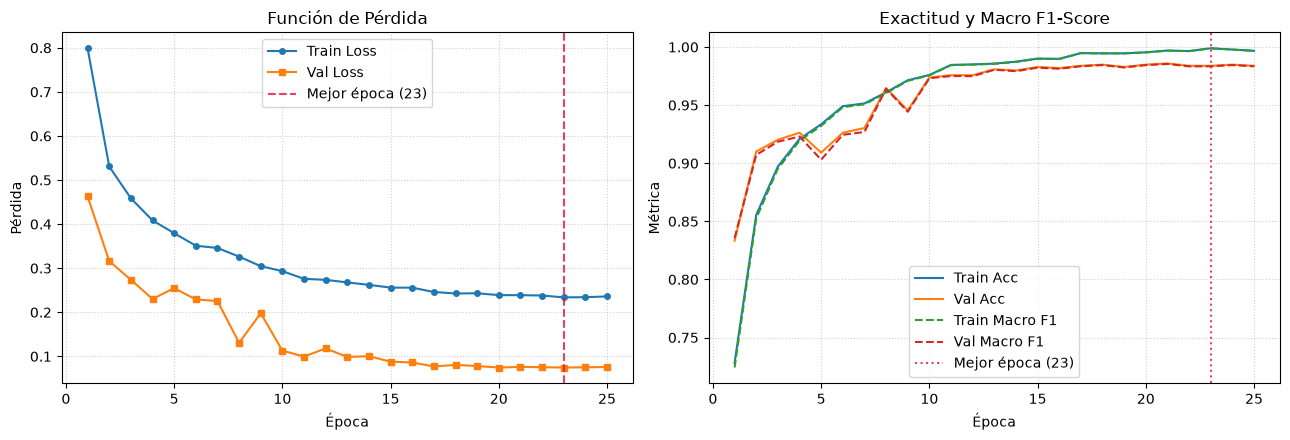

In [20]:
best_idx = history_df["val_loss"].idxmin()
best_row = history_df.loc[best_idx]
best_epoch = int(best_row["epoch"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o", markersize=4, label="Train Loss")
axes[0].plot(history_df["epoch"], history_df["val_loss"], marker="s", markersize=4, label="Val Loss")
axes[0].axvline(best_epoch, color="crimson", linestyle="--", alpha=0.8, label=f"Mejor época ({best_epoch})")
axes[0].set_title("Función de Pérdida")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Pérdida")
axes[0].grid(True, linestyle=":", alpha=0.6)
axes[0].legend()

axes[1].plot(history_df["epoch"], history_df["train_acc"], linestyle="-", label="Train Acc")
axes[1].plot(history_df["epoch"], history_df["val_acc"], linestyle="-", label="Val Acc")
axes[1].plot(history_df["epoch"], history_df["train_f1"], linestyle="--", label="Train Macro F1")
axes[1].plot(history_df["epoch"], history_df["val_f1"], linestyle="--", label="Val Macro F1")
axes[1].axvline(best_epoch, color="crimson", linestyle=":", alpha=0.8, label=f"Mejor época ({best_epoch})")
axes[1].set_title("Exactitud y Macro F1-Score")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Métrica")
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.show()

### 3.2. Desempeño Cuantitativo en el Conjunto de Prueba (`Test`)
Restaurados los pesos de la mejor época de validación (época 23), se evalúa la capacidad de generalización de `DoubleConvMRICNN` sobre el conjunto de prueba independiente (`n = 990` imágenes), obteniendo **`Test Loss: 0.0716`**, **`Test Accuracy: 98.79 %`** ($978/990$ aciertos y solo $12$ errores) y **`Test Macro F1: 98.75 %`**, con un desempeño sobresaliente en las cuatro categorías (`pituitary F1: 99.62 %`, `healthy F1: 99.03 %`, `glioma F1: 98.97 %` y `meningioma F1: 97.38 %`). Se reporta el detalle por clase junto con la matriz de confusión absoluta y porcentual (exportada también a `latex_MRI/figs/confusion_matrix.pdf`).

Resultados en Test (n=990) -> Test Loss: 0.0716 | Test Accuracy: 0.9879 | Test Macro F1: 0.9875

              precision    recall  f1-score   support

      glioma     0.9877    0.9918    0.9897       243
  meningioma     0.9781    0.9696    0.9738       230
     healthy     0.9883    0.9922    0.9903       256
   pituitary     0.9962    0.9962    0.9962       261

    accuracy                         0.9879       990
   macro avg     0.9876    0.9874    0.9875       990
weighted avg     0.9879    0.9879    0.9879       990



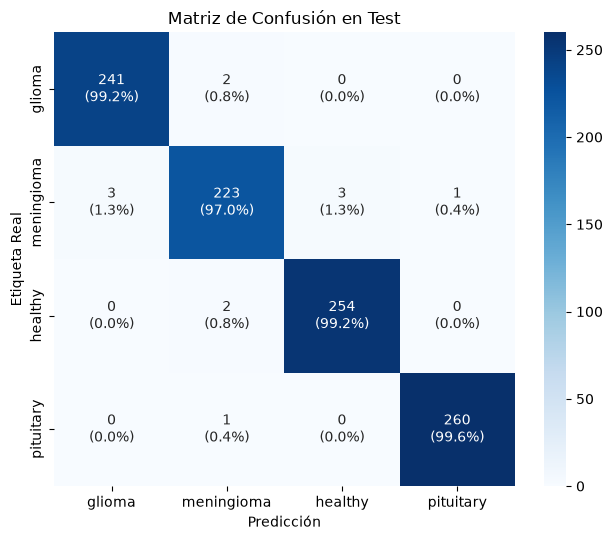

In [21]:
test_loss, test_acc, test_f1, y_true, y_pred = evaluate(
    custom_model, test_loader, criterion, device
)

print(
    f"Resultados en Test (n={len(y_true)}) -> "
    f"Test Loss: {test_loss:.4f} | "
    f"Test Accuracy: {test_acc:.4f} | "
    f"Test Macro F1: {test_f1:.4f}\n"
)
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))

cm = confusion_matrix(y_true, y_pred)
cm_perc = cm.astype("float") / cm.sum(axis=1, keepdims=True) * 100
annot_labels = np.array([
    [f"{count}\n({perc:.1f}%)" for count, perc in zip(row_c, row_p)]
    for row_c, row_p in zip(cm, cm_perc)
])

fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(
    cm, annot=annot_labels, fmt="", cmap="Blues", cbar=True,
    xticklabels=CLASSES, yticklabels=CLASSES, ax=ax
)
ax.set_title("Matriz de Confusión en Test")
ax.set_xlabel("Predicción")
ax.set_ylabel("Etiqueta Real")

plt.tight_layout()
Path("latex_MRI/figs").mkdir(parents=True, exist_ok=True)
fig.savefig("latex_MRI/figs/confusion_matrix.pdf", bbox_inches="tight")
plt.show()

### 3.3. Análisis Cualitativo de Predicciones
Se presenta una inspección visual sobre muestras del conjunto de prueba (`Test`, $n = 990$) contrastando la etiqueta clínica real (*ground truth*) frente a la predicción asignada por `DoubleConvMRICNN` y su probabilidad de confianza (`softmax`). En primer lugar se tabulan los pares de confusión observados entre los **12 errores** del conjunto de prueba —todos ellos asociados a la frontera diagnóstica de `meningioma` (`meningioma -> glioma`: 3 casos, `meningioma -> healthy`: 3, `glioma -> meningioma`: 2, `healthy -> meningioma`: 2, `meningioma -> pituitary`: 1 y `pituitary -> meningioma`: 1)— con confianzas medias moderadas ($44.9\,\% - 78.6\,\%$). Posteriormente, se visualiza una grilla comparativa con 4 aciertos representativos (uno por cada categoría diagnóstica) en la fila superior y 4 casos de error entre patologías en la fila inferior.

Total de aciertos en Test: 978/990 | Total de errores: 12


casos  confianza_media_pct
true_label pred_label                            
meningioma glioma          3            62.270000
           healthy         3            78.269997
glioma     meningioma      2            53.480000
healthy    meningioma      2            69.480003
meningioma pituitary       1            44.930000
pituitary  meningioma      1            78.550003

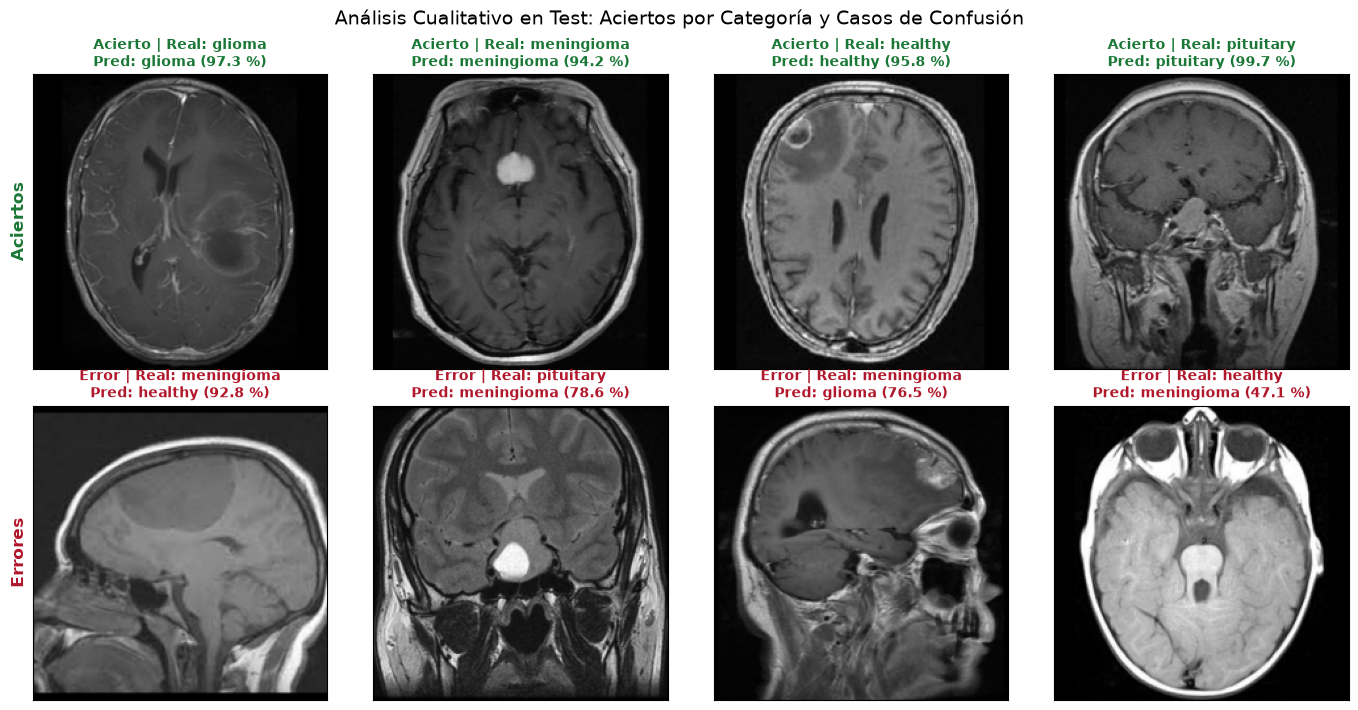

In [22]:
# Visualización cualitativa de predicciones correctas y errores de clasificación en Test
custom_model.eval()
all_probs, all_preds, all_targets = [], [], []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)
        logits = custom_model(inputs)
        probs = torch.softmax(logits, dim=1)
        all_probs.append(probs.cpu().numpy())
        all_preds.append(probs.argmax(dim=1).cpu().numpy())
        all_targets.append(targets.numpy())

test_probs = np.concatenate(all_probs, axis=0)
y_pred_qual = np.concatenate(all_preds, axis=0)
y_true_qual = np.concatenate(all_targets, axis=0)

df_qual = df_test.copy()
df_qual["true_label"] = [IDX_TO_CLASS[i] for i in y_true_qual]
df_qual["pred_label"] = [IDX_TO_CLASS[i] for i in y_pred_qual]
df_qual["confidence_pct"] = (test_probs.max(axis=1) * 100).round(2)
df_qual["correct"] = y_true_qual == y_pred_qual

df_errors = df_qual[~df_qual["correct"]]
print(f"Total de aciertos en Test: {df_qual['correct'].sum()}/{len(df_qual)} | Total de errores: {len(df_errors)}")

df_error_pairs = (
    df_errors.groupby(["true_label", "pred_label"])
    .agg(casos=("filepath", "size"), confianza_media_pct=("confidence_pct", "mean"))
    .round(2)
    .sort_values("casos", ascending=False)
)
display(df_error_pairs)

# Selección determinista: 1 acierto por clase (fila 1) y 4 errores diversos entre clases (fila 2)
correct_samples = [
    df_qual[df_qual["correct"] & (df_qual["true_label"] == cls_name)].iloc[0]
    for cls_name in CLASSES
]

diverse_errors = df_errors.groupby(["true_label", "pred_label"], as_index=False).first()
if len(diverse_errors) < 4:
    extra_errors = df_errors.drop(index=diverse_errors.index, errors="ignore").head(4 - len(diverse_errors))
    error_samples_df = pd.concat([diverse_errors, extra_errors], ignore_index=True).head(4)
else:
    error_samples_df = diverse_errors.sort_values("confidence_pct", ascending=False).head(4)

fig, axes = plt.subplots(2, 4, figsize=(14, 7.2))

for col, record in enumerate(correct_samples):
    idx = record.name
    img_gray = test_dataset.images[idx].convert("L")
    axes[0, col].imshow(img_gray, cmap="gray")
    axes[0, col].set_title(
        f"Acierto | Real: {record['true_label']}\nPred: {record['pred_label']} ({record['confidence_pct']:.1f} %)",
        fontsize=10, color="#1b7837", fontweight="bold"
    )
    axes[0, col].set_xticks([])
    axes[0, col].set_yticks([])

for col, (_, record) in enumerate(error_samples_df.iterrows()):
    idx = df_qual[df_qual["filepath"] == record["filepath"]].index[0]
    img_gray = test_dataset.images[idx].convert("L")
    axes[1, col].imshow(img_gray, cmap="gray")
    axes[1, col].set_title(
        f"Error | Real: {record['true_label']}\nPred: {record['pred_label']} ({record['confidence_pct']:.1f} %)",
        fontsize=10, color="#b2182b", fontweight="bold"
    )
    axes[1, col].set_xticks([])
    axes[1, col].set_yticks([])

axes[0, 0].set_ylabel("Aciertos", fontsize=12, fontweight="bold", color="#1b7837")
axes[1, 0].set_ylabel("Errores", fontsize=12, fontweight="bold", color="#b2182b")
fig.suptitle("Análisis Cualitativo en Test: Aciertos por Categoría y Casos de Confusión", fontsize=14)
plt.tight_layout()
Path("latex_MRI/figs").mkdir(parents=True, exist_ok=True)
fig.savefig("latex_MRI/figs/qualitative_predictions.pdf", bbox_inches="tight")
plt.show()

---
## 4. Discusión y Conclusiones
- **Síntesis de resultados y comparación de arquitecturas:** La incorporación de una fase de exploración rápida sobre un subconjunto estratificado extraído exclusivamente desde `Train` ($30\,\%$ de `df_train`: $969$ imágenes de entrenamiento, $208$ de validación y $208$ de prueba, durante $15$ épocas) permitió comparar objetivamente cuatro propuestas sin tocar los conjuntos globales de validación ni de prueba. Los experimentos demostraron que: (i) reemplazar `ReduceLROnPlateau` (`lr=1e-3`) por `CosineAnnealingLR` (`lr=8e-4`) con `label_smoothing=0.05` y recorte de gradiente (`max_norm=2.0`) en `BaselineCNN` ($422\,308$ parámetros) reduce los picos de pérdida en validación (`Max Spike` de `2.1688` a `1.2724`) y eleva la exactitud en `Sub-Test` de **`80.29 %`** a **`85.10 %`** (*Macro F1* de `79.30 %` a `84.56 %`); (ii) extender la red a 5 bloques e incorporar agrupación global dual en `Deep5BlockCNN` ($1.83\text{M}$ parámetros) eleva la exactitud en el subconjunto a **`93.75 %`** (*Macro F1*: `93.59 %`, `Test Loss: 0.1566`); y (iii) la arquitectura **`DoubleConvMRICNN`** (4 bloques de doble convolución $3 \times 3$, agrupación global dual `AvgPool + MaxPool` y `BatchNorm1d`, con $1.24\text{M}$ parámetros) alcanza la mayor capacidad de generalización en el subconjunto con **`Test Accuracy: 96.15 %`**, **`Test Macro F1: 95.99 %`** y **`Test Loss: 0.1684`** empleando un $32.4\,\%$ menos de parámetros que el modelo de 5 bloques. Al entrenarse durante $25$ épocas sobre el $100\,\%$ de la partición de entrenamiento ($4\,617$ imágenes), `DoubleConvMRICNN` alcanzó su punto óptimo en la época 23 (`Val Loss: 0.0746`, `Val Acc: 98.38 %`, `Val Macro F1: 98.34 %`) y obtuvo sobre el conjunto de prueba definitivo ($n = 990$) un **`Test Accuracy: 98.79 %`** ($978/990$ aciertos), **`Test Macro F1: 98.75 %`** y **`Test Loss: 0.0716`**.
- **Análisis por categoría tumoral:** En la evaluación final sobre el conjunto de prueba ($n = 990$), las categorías `pituitary` (`Precision: 99.62 %`, `Recall: 99.62 %`, **`F1: 99.62 %`**), `healthy` (`Precision: 98.83 %`, `Recall: 99.22 %`, **`F1: 99.03 %`**) y `glioma` (`Precision: 98.77 %`, `Recall: 99.18 %`, **`F1: 98.97 %`**) superan el $98.9\,\%$ de *F1-Score* gracias a la localización focalizada de los adenomas hipofisarios en la región selar, la regularidad anatómica del parénquima sano y la captura del patrón infiltrativo glial. El mayor reto diagnóstico radica en `meningioma` (`Precision: 97.81 %`, `Recall: 96.96 %`, **`F1: 97.38 %`**), que interviene en la totalidad de los 12 errores observados en `Test` (7 falsos negativos y 5 falsos positivos); no obstante, la combinación de bloques de doble convolución $3 \times 3$ (campo receptivo efectivo $5 \times 5$ con doble no-linealidad) y *Dual Global Pooling* permitió elevar su *F1-Score* desde `59.77 %` (`BaselineCNN` base en el subconjunto) hasta `97.38 %` en el modelo final.
- **Limitaciones y trabajo futuro:** Dado que el conjunto de datos público carece de metadatos de identificación por paciente, cortes bidimensionales próximos provenientes de un mismo estudio volumétrico MRI podrían guardar correlación anatómica entre particiones a pesar de la eliminación rigurosa de duplicados exactos mediante hash MD5. Como trabajo futuro se plantea incorporar mapas de atribución visual (*Grad-CAM*) sobre los aciertos y los 12 casos de confusión identificados en el análisis cualitativo (sección 3.3) para auditar clínicamente que las activaciones del clasificador se concentren sobre la lesión tumoral.